In [12]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()
SHOTS = 100

## Prediction

The original Bell-state circuit applies an H gate to the first qubit and a CNOT gate controlled by the first qubit. When both qubits are measured, the outcomes `00` and `11` are expected, each with approximately 50% probability.

In the modified circuit, an X gate is added to the second qubit after the CNOT gate. This flips the second qubit, so the expected outcomes become `01` and `10`, each with approximately 50% probability.

Therefore, the original circuit produces correlated outcomes, while the modified circuit produces anti-correlated outcomes.

In [13]:
# Original Bell-state circuit
original = QuantumCircuit(2, 2)

original.h(0)
original.cx(0, 1)

original.measure(0, 0)
original.measure(1, 1)


# Modified Bell-state circuit
modified = QuantumCircuit(2, 2)

modified.h(0)
modified.cx(0, 1)
modified.x(1)  # Added one X gate to qubit 1

modified.measure(0, 0)
modified.measure(1, 1)

Original Bell-State Circuit:


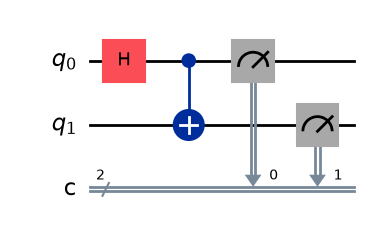

Modified Bell-State Circuit:


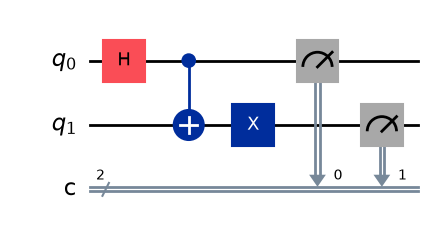

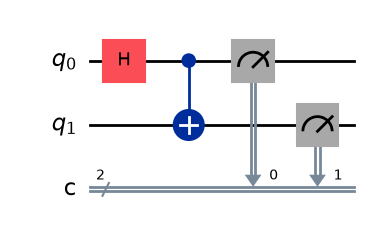

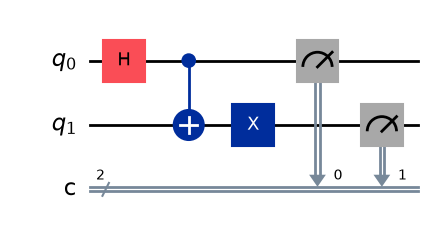

In [14]:
print("Original Bell-State Circuit:")
display(original.draw("mpl"))

print("Modified Bell-State Circuit:")
display(modified.draw("mpl"))

In [15]:
# Execute original circuit
original_job = simulator.run(original, shots=SHOTS)
original_counts = original_job.result().get_counts()

# Execute modified circuit
modified_job = simulator.run(modified, shots=SHOTS)
modified_counts = modified_job.result().get_counts()

print("Original Bell-State Results:")
print(original_counts)
print("Total shots:", sum(original_counts.values()))

print("\nModified Bell-State Results:")
print(modified_counts)
print("Total shots:", sum(modified_counts.values()))

Original Bell-State Results:
{'11': 50, '00': 50}
Total shots: 100

Modified Bell-State Results:
{'01': 51, '10': 49}
Total shots: 100


In [16]:
import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram

In [17]:
%matplotlib inline

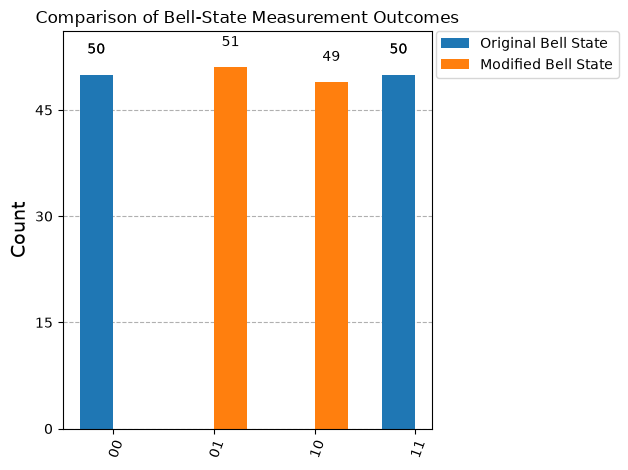

In [18]:
plot_histogram(
    [original_counts, modified_counts],
    legend=["Original Bell State", "Modified Bell State"],
    title="Comparison of Bell-State Measurement Outcomes"
)

plt.show()

In [19]:
print("COMPARISON OF MEASUREMENT RESULTS")
print("-" * 40)

print("\nOriginal Circuit:")
for outcome in ["00", "01", "10", "11"]:
    count = original_counts.get(outcome, 0)
    print(f"{outcome}: {count} shots ({count}%)")

print("\nModified Circuit:")
for outcome in ["00", "01", "10", "11"]:
    count = modified_counts.get(outcome, 0)
    print(f"{outcome}: {count} shots ({count}%)")

COMPARISON OF MEASUREMENT RESULTS
----------------------------------------

Original Circuit:
00: 50 shots (50%)
01: 0 shots (0%)
10: 0 shots (0%)
11: 50 shots (50%)

Modified Circuit:
00: 0 shots (0%)
01: 51 shots (51%)
10: 49 shots (49%)
11: 0 shots (0%)


## Comparison and Conclusion

The original Bell-state circuit creates an entangled state:

\[
|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}
\]

Therefore, the measurement outcomes `00` and `11` occur with approximately equal probability. Both qubits produce the same measurement result.

In the modified circuit, an X gate is applied to the second qubit. The X gate flips that qubit, transforming the state into:

\[
|\Psi^+\rangle = \frac{|01\rangle + |10\rangle}{\sqrt{2}}
\]

Consequently, the outcomes `01` and `10` become the only expected measurement results. The two qubits now produce opposite outcomes.

This experiment demonstrates that adding a single quantum gate can change the correlation between two entangled qubits from correlated to anti-correlated, while preserving their entanglement.